In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
data=pd.read_csv("spam.csv",encoding="latin-1")
data.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
3027,ham,You have got tallent but you are wasting.,NaN,NaN,NaN
4724,ham,There'll be a minor shindig at my place later ...,NaN,NaN,NaN
2877,spam,Hey Boys. Want hot XXX pics sent direct 2 ur p...,NaN,NaN,NaN
2325,ham,Apps class varaya elaya.,NaN,NaN,NaN
1926,ham,Dont give a monkeys wot they think and i certa...,NaN,NaN,NaN


In [9]:
data.shape

(5572, 5)

In [10]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB


In [11]:
# Keep a copy of the original dataset
data_raw = data.copy()

# Merge extra message parts into the main message
extra_columns = ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

data['v2'] = data[['v2'] + extra_columns].apply(
    lambda row: ' '.join(str(x) for x in row if pd.notna(x)),
    axis=1
)

In [12]:
data.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)


In [13]:
data.sample(5)

,v1,v2
5145,ham,Aiyar u so poor thing... I give u my support k...
4458,spam,Welcome to UK-mobile-date this msg is FREE giv...
5148,ham,K..then come wenever u lik to come and also te...
791,ham,All e best 4 ur driving tmr :-)
3639,ham,He's really into skateboarding now despite the...


In [14]:
#check for missing values
data.isnull().sum()

v1    0
v2    0
dtype: int64

In [15]:
#check foe duplication
data.duplicated().sum()

403

In [16]:
#Remove duplication
data.drop_duplicates(keep='first',inplace=True)


In [17]:
data.duplicated().sum()

0

In [18]:
data.shape

(5169, 2)

In [19]:
#Renaming columns
data.rename(columns={'v1':'Target','v2':'Text'},inplace=True)
data.sample(7)

,Target,Text
4796,spam,Santa calling! Would your little ones like a c...
4955,ham,Ahhhh...just woken up!had a bad dream about u ...
2256,ham,"Just checked out, heading out to drop off my s..."
4330,ham,Nope i'll come online now..
5101,ham,Nope thats fine. I might have a nap tho!
911,ham,I am sorry it hurt you.
935,ham,Then dun wear jeans lor...


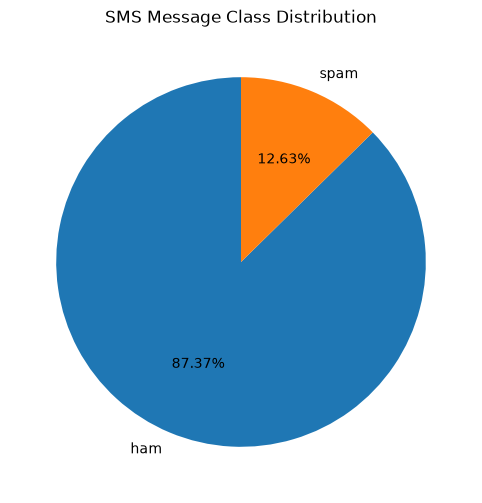

In [20]:
data['Target'].value_counts().plot(
    kind='pie',
    autopct='%1.2f%%',
    figsize=(6, 6),
    startangle=90
)

plt.ylabel('')
plt.title('SMS Message Class Distribution')
plt.show()

In [21]:
data['Target'].value_counts()

Target
ham     4516
spam     653
Name: count, dtype: int64

In [22]:
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\omars\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\omars\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [23]:
data['num_words']=data['Text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [24]:
data.head()

,Target,Text,num_words
0,ham,"Go until jurong point, crazy.. Available only ...",24
1,ham,Ok lar... Joking wif u oni...,8
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,37
3,ham,U dun say so early hor... U c already then say...,13
4,ham,"Nah I don't think he goes to usf, he lives aro...",15


In [25]:
data.groupby('Target')['num_words'].describe()

,count,mean,std,min,25%,50%,75%,max
Target,,,,,,,,
ham,4516.0,17.275465,13.586125,1.0,8.0,13.0,22.0,220.0
spam,653.0,27.754977,6.980780,2.0,25.0,29.0,32.0,46.0


In [26]:
import seaborn as sns

In [27]:
#data preprosissing
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\omars\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [28]:

from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
import nltk
import re
import string

ps = PorterStemmer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', '', text)
    tokens = nltk.word_tokenize(text)

    cleaned_text = []
    for word in tokens:
        if word.isalpha():
            if word not in stop_words:
                cleaned_text.append(ps.stem(word))

    return " ".join(cleaned_text)


In [29]:
clean_text('FREE RINGTONE text?  FIRST to 87131 for  the a <fttyty?> poly or text GET&gf764744 to 87131 for a true tone! Help? 0845 2814032 16 after 1st free, tones are 3xå£150pw to eå£nd txt stop')

'free rington text first poli text get true tone help free tone txt stop'

In [30]:
data['Cleaned_Text'] = data['Text'].apply(clean_text)

In [31]:
data.head()

,Target,Text,num_words,Cleaned_Text
0,ham,"Go until jurong point, crazy.. Available only ...",24,go jurong point crazi avail bugi n great world...
1,ham,Ok lar... Joking wif u oni...,8,ok lar joke wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,37,free entri wkli comp win fa cup final tkt may ...
3,ham,U dun say so early hor... U c already then say...,13,u dun say earli hor u c alreadi say
4,ham,"Nah I don't think he goes to usf, he lives aro...",15,nah think goe usf live around though


In [32]:
(data['Cleaned_Text'].str.strip() == '').sum()

11

In [33]:
empty_messages = data[data['Cleaned_Text'].str.strip() == '']

empty_messages[['Text', 'Cleaned_Text', 'Target']]

,Text,Cleaned_Text,Target
252,What you doing?how are you?,,ham
959,Where @,,ham
1611,645,,ham
2805,Can a not?,,ham
3092,staff.science.nus.edu.sg/~phyhcmk/teaching/pc1323,,ham
3374,:),,ham
3740,2/2 146tf150p,,spam
4291,G.W.R,,ham
4573,:( but your not here....,,ham
4822,:-) :-),,ham


In [34]:
empty_messages['Target'].value_counts()

Target
ham     10
spam     1
Name: count, dtype: int64

In [35]:
data = data[data['Cleaned_Text'].str.strip() != '']

data.shape

(5158, 4)

In [36]:
from sklearn.preprocessing import LabelEncoder
encoder =LabelEncoder()
data['Target']=encoder.fit_transform(data['Target'])

In [37]:
data.sample(10)



,Target,Text,num_words,Cleaned_Text
605,0,TaKe CaRE n gET WeLL sOOn,6,take care n get well soon
3757,0,Lol no ouch but wish i'd stayed out a bit longer,12,lol ouch wish stay bit longer
3233,0,Yup Ì_ not comin :-(,7,yup comin
2214,0,Ok then i'll let him noe later n ask him call ...,15,ok let noe later n ask call u tmr
3553,0,am up to my eyes in philosophy,7,eye philosophi
5086,0,Omg if its not one thing its another. My cat h...,22,omg one thing anoth cat worm bad day end
3620,0,That means from february to april i'll be gett...,40,mean februari april get place stay hustl back ...
4674,1,"Hi babe its Chloe, how r u? I was smashed on s...",37,hi babe chloe r u smash saturday night great w...
2513,1,U have won a nokia 6230 plus a free digital ca...,35,u nokia plu free digit camera u get u win free...
129,0,K..k:)how much does it cost?,11,k k much cost


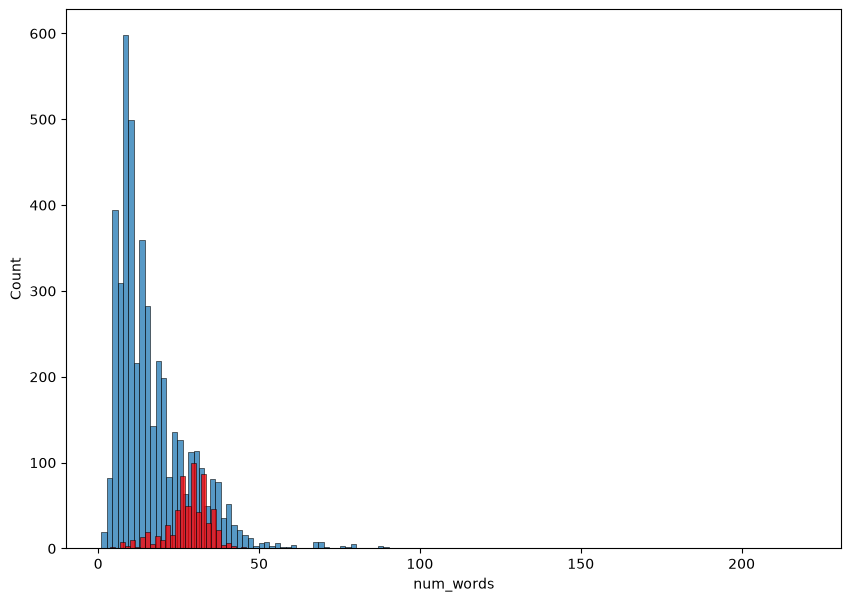

In [38]:
plt.figure(figsize=(10,7))
sns.histplot(data[data["Target"]==0]["num_words"])
sns.histplot(data[data["Target"]==1]["num_words"],color="red")
plt.show()


In [39]:
from sklearn.model_selection import train_test_split
X = data['Cleaned_Text']
y = data['Target']
x_train, x_test, y_train, y_test = train_test_split(data['Cleaned_Text'],data['Target'],test_size=0.15,random_state=42,stratify=data['Target'])

In [40]:
print(x_train.shape)
print(x_test.shape)

print(y_train.shape)
print(y_test.shape)

(4384,)
(774,)
(4384,)
(774,)


In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

In [42]:
#Modeling
from sklearn.model_selection import GridSearchCV, cross_val_predict,StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import precision_score , recall_score , f1_score , confusion_matrix , accuracy_score , roc_curve, roc_auc_score

In [43]:
# Create Logistic Regression Pipeline
log_reg_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, max_df=0.85, sublinear_tf=True, analyzer='word', ngram_range=(1,2))),
    ('classifier', LogisticRegression(C=1, max_iter=1000, random_state=42, class_weight='balanced'))
])
# Create Stratified
skf = StratifiedKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

# Apply Cross Validation on Training Data
y_val_pred = cross_val_predict(
    log_reg_pipeline,
    x_train,
    y_train,
    cv=skf,
    method='predict',
    n_jobs=-1
)

print("Validation Accuracy:", accuracy_score(y_train, y_val_pred))
print("Precision:", precision_score(y_train, y_val_pred))
print("Recall:", recall_score(y_train, y_val_pred))
print("F1 Score:", f1_score(y_train, y_val_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_train, y_val_pred))


Validation Accuracy: 0.968978102189781
Precision: 0.856655290102389
Recall: 0.9061371841155235
F1 Score: 0.8807017543859649
Confusion Matrix:
[[3746   84]
 [  52  502]]


In [44]:
linear_svc_pipeline =Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, max_df=0.85, sublinear_tf=True, analyzer='word', ngram_range=(1,2))),
    ('classifier', LinearSVC(C=1, max_iter=1000, random_state=42, class_weight='balanced'))
])    
# Create Stratified 
skf = StratifiedKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)


y_val_pred_svm = cross_val_predict(
    linear_svc_pipeline,
    x_train,
    y_train,
    cv=skf,
    method='predict',
    n_jobs=-1
)

print("Validation Accuracy:", accuracy_score(y_train, y_val_pred_svm))
print("Precision:", precision_score(y_train, y_val_pred_svm))
print("Recall:", recall_score(y_train, y_val_pred_svm))
print("F1 Score:", f1_score(y_train, y_val_pred_svm))
print("Confusion Matrix:")
print(confusion_matrix(y_train, y_val_pred_svm))

Validation Accuracy: 0.979470802919708
Precision: 0.9377358490566038
Recall: 0.8971119133574007
F1 Score: 0.9169741697416974
Confusion Matrix:
[[3797   33]
 [  57  497]]


In [45]:
param_grid_lr = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (2, 3)],
    'tfidf__max_df': [0.6, 0.7, 0.8],
    'tfidf__max_features': [5000, 3000],
    'classifier__C': [0.1, 1, 100, 10],
    'classifier__class_weight': [None, 'balanced']
}

In [46]:

grid_lr = GridSearchCV(
    estimator=log_reg_pipeline,
    param_grid=param_grid_lr,
    scoring='accuracy',
    cv=skf,
    n_jobs=-1,
    verbose=1
)
grid_lr.fit(x_train, y_train)
print("Best Parameters:", grid_lr.best_params_)
print("Best Cross-Validation accuracy:", grid_lr.best_score_)

Fitting 6 folds for each of 144 candidates, totalling 864 fits
Best Parameters: {'classifier__C': 100, 'classifier__class_weight': 'balanced', 'tfidf__max_df': 0.6, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 1)}
Best Cross-Validation accuracy: 0.9806089112930932


In [47]:
param_grid_svm = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (2, 3)],
    'tfidf__max_df': [0.6, 0.7, 0.8],
    'classifier__C': [0.1, 1, 100, 10],
    'classifier__class_weight': [None, 'balanced']
}

In [48]:

grid_svm = GridSearchCV(
    estimator=linear_svc_pipeline,
    param_grid=param_grid_svm,
    scoring='accuracy',
    cv=skf,
    n_jobs=-1,
    verbose=1
)
grid_svm.fit(x_train, y_train)
print("Best Parameters:", grid_svm.best_params_)
print("Best Cross-Validation accuracy:", grid_svm.best_score_)

Fitting 6 folds for each of 72 candidates, totalling 432 fits


Best Parameters: {'classifier__C': 1, 'classifier__class_weight': None, 'tfidf__max_df': 0.6, 'tfidf__ngram_range': (1, 2)}
Best Cross-Validation accuracy: 0.979925853743855


In [50]:
y_val_pred_lr_tuned = cross_val_predict(
    grid_lr.best_estimator_,
    x_train,
    y_train,
    cv=skf,
    method='predict',
    n_jobs=-1
)

In [51]:
print("Validation Accuracy:", accuracy_score(y_train, y_val_pred_lr_tuned))
print("Precision:", precision_score(y_train, y_val_pred_lr_tuned))
print("Recall:", recall_score(y_train, y_val_pred_lr_tuned))
print("F1 Score:", f1_score(y_train, y_val_pred_lr_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_train, y_val_pred_lr_tuned))

Validation Accuracy: 0.9806113138686131
Precision: 0.9449715370018975
Recall: 0.8989169675090253
F1 Score: 0.9213691026827012
Confusion Matrix:
[[3801   29]
 [  56  498]]


In [52]:
y_val_pred_svm_tuned = cross_val_predict(
    grid_svm.best_estimator_,
    x_train,
    y_train,
    cv=skf,
    method='predict',
    n_jobs=-1
)

In [53]:
print("Validation Accuracy:", accuracy_score(y_train, y_val_pred_svm_tuned))
print("Precision:", precision_score(y_train, y_val_pred_svm_tuned))
print("Recall:", recall_score(y_train, y_val_pred_svm_tuned))
print("F1 Score:", f1_score(y_train, y_val_pred_svm_tuned))

print("Confusion Matrix:")
print(confusion_matrix(y_train, y_val_pred_svm_tuned))


Validation Accuracy: 0.9799270072992701
Precision: 0.9641434262948207
Recall: 0.8736462093862816
F1 Score: 0.9166666666666666
Confusion Matrix:
[[3812   18]
 [  70  484]]


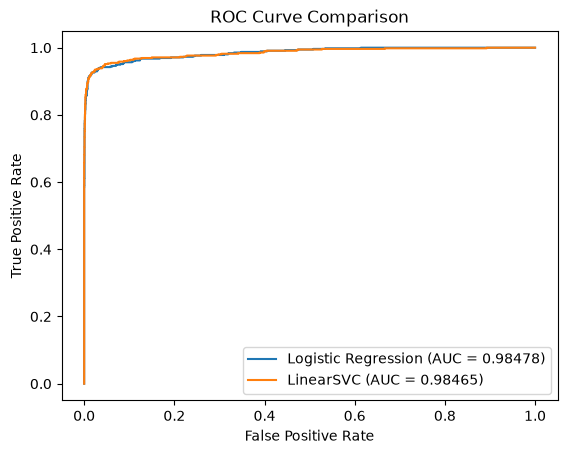

In [54]:
# ROC AUC

y_val_proba_log_reg = cross_val_predict(
    grid_lr.best_estimator_,
    x_train,
    y_train,
    cv=skf,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

fpr_log_reg, tpr_log_reg, _ = roc_curve(y_train, y_val_proba_log_reg)
roc_auc_log_reg = roc_auc_score(y_train, y_val_proba_log_reg)


y_val_proba_linearsvc = cross_val_predict(
    grid_svm.best_estimator_,
    x_train,
    y_train,
    cv=skf,
    method='decision_function',
    n_jobs=-1
)

fpr_linearsvc, tpr_linearsvc, _ = roc_curve(y_train, y_val_proba_linearsvc)
roc_auc_linearsvc = roc_auc_score(y_train, y_val_proba_linearsvc)


plt.plot(fpr_log_reg, tpr_log_reg, label=f'Logistic Regression (AUC = {roc_auc_log_reg:.5f})')
plt.plot(fpr_linearsvc, tpr_linearsvc, label=f'LinearSVC (AUC = {roc_auc_linearsvc:.5f})')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

In [55]:
best_lr_model = grid_lr.best_estimator_

In [56]:
best_svm_model = grid_svm.best_estimator_

In [57]:
# Vocabulary Size

print("Logistic Regression Vocabulary Size:",
    len(grid_lr.best_estimator_.named_steps['tfidf'].get_feature_names_out()))

print("Linear SVM Vocabulary Size:",
    len(grid_svm.best_estimator_.named_steps['tfidf'].get_feature_names_out()))

Logistic Regression Vocabulary Size: 5000
Linear SVM Vocabulary Size: 5000


In [58]:
y_test_pred_lr = best_lr_model.predict(x_test)

y_test_pred_svm = best_svm_model.predict(x_test)

In [59]:
# Logistic Regression Test Evaluation
print("Logistic Regression Test Results")
print("Accuracy:", accuracy_score(y_test, y_test_pred_lr))
print("Precision:", precision_score(y_test, y_test_pred_lr))
print("Recall:", recall_score(y_test, y_test_pred_lr))
print("F1 Score:", f1_score(y_test, y_test_pred_lr))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_lr))

Logistic Regression Test Results
Accuracy: 0.9909560723514211
Precision: 0.9690721649484536
Recall: 0.9591836734693877
F1 Score: 0.9641025641025641
Confusion Matrix:
[[673   3]
 [  4  94]]


In [60]:

# Linear SVM Test Evaluation
print("Linear SVM Test Results")
print("Accuracy:", accuracy_score(y_test, y_test_pred_svm))
print("Precision:", precision_score(y_test, y_test_pred_svm))
print("Recall:", recall_score(y_test, y_test_pred_svm))
print("F1 Score:", f1_score(y_test, y_test_pred_svm))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_svm))

Linear SVM Test Results
Accuracy: 0.9909560723514211
Precision: 1.0
Recall: 0.9285714285714286
F1 Score: 0.9629629629629629
Confusion Matrix:
[[676   0]
 [  7  91]]


In [61]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report")
print(classification_report(y_test, y_test_pred_lr))

print("Linear SVM Classification Report")
print(classification_report(y_test, y_test_pred_svm))

Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       676
           1       0.97      0.96      0.96        98

    accuracy                           0.99       774
   macro avg       0.98      0.98      0.98       774
weighted avg       0.99      0.99      0.99       774

Linear SVM Classification Report
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       676
           1       1.00      0.93      0.96        98

    accuracy                           0.99       774
   macro avg       0.99      0.96      0.98       774
weighted avg       0.99      0.99      0.99       774



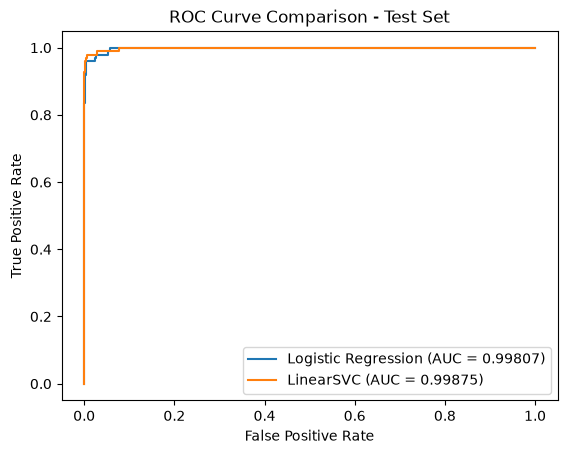

In [62]:
# ROC AUC - Test Set

y_test_proba_log_reg = best_lr_model.predict_proba(x_test)[:, 1]

fpr_log_reg_test, tpr_log_reg_test, _ = roc_curve(y_test, y_test_proba_log_reg)
roc_auc_log_reg_test = roc_auc_score(y_test, y_test_proba_log_reg)


y_test_proba_linearsvc = best_svm_model.decision_function(x_test)

fpr_linearsvc_test, tpr_linearsvc_test, _ = roc_curve(y_test, y_test_proba_linearsvc)
roc_auc_linearsvc_test = roc_auc_score(y_test, y_test_proba_linearsvc)


plt.plot(fpr_log_reg_test, tpr_log_reg_test, label=f'Logistic Regression (AUC = {roc_auc_log_reg_test:.5f})')
plt.plot(fpr_linearsvc_test, tpr_linearsvc_test, label=f'LinearSVC (AUC = {roc_auc_linearsvc_test:.5f})')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - Test Set')
plt.legend()
plt.show()

Metric	Logistic Regression (CV)	Linear SVM (CV)	Logistic Regression (Test)	Linear SVM (Test)
| Metric | Logistic Regression | Linear SVM |
|---|---:|---:|
| Accuracy | 99.10% | 99.10% |
| Precision | 96.91% | 100% |
| Recall | 95.92% | 92.86% |
| F1-score | 96.41% | 96.30% |
| ROC AUC | 0.99807 | 0.99875 |


In [63]:
import joblib

joblib.dump(best_lr_model, 'logistic_regression_model.pkl')
joblib.dump(best_svm_model, 'linear_svm_model.pkl')

['linear_svm_model.pkl']